# Exercise 1 

In this exercise, we will work with the `spam.csv` data file. This file contains text and a label attached to each text. The goal is to clean the text data and then build classifcation models. 

### Exercise 1(a) (2 points)

Load the `pandas` and `numpy` libraries.

In [11]:
import pandas as pd
import numpy as np

### Exercise 1(b) (2 points)

Read the `csv` file and create a data-frame called `spam_df`.

In [12]:
spam_df = pd.read_csv("spam.csv")
spam_df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### Exercise 1(c) (2 points)

Using the `string` library, remove all the punctuation of the `text` column.

In [13]:
import string

spam_df['text_clean'] = spam_df['text'].str.replace(f"[{string.punctuation}]", "", regex=True)
spam_df.head()

,label,text,text_clean
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...


### Exercise 1(d) (10 points)

Using the `nltk` library, remove stopwords and pronouns from `text_clean` and store in another column called `'text_clean_1'`. 

In [14]:
import nltk
nltk.download('punkt')
nltk.download('stopwords')

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

stop_words = set(stopwords.words('english'))
pronouns = ['i', 'me', 'my', 'mine', 'you', 'your', 'yours', 'he', 'him', 'his', 'she', 'her', 'hers', 'we', 'us', 'our', 'ours', 'they', 'them', 'their', 'theirs', 'u', 'ur', 'im', 'dont', '2', 'ill', '4']

def clean_text(text):
    #tokenize the text
    tokens = word_tokenize(text.lower())

    #remove unwanted tokens (stop words and pronouns)
    tokens = [token for token in tokens if token not in stop_words and token not in pronouns]

    #replacing words
    tokens = [word.replace('txt', 'text') for word in tokens]

    return " ".join(tokens)

spam_df['text_clean_1'] = spam_df['text_clean'].apply(clean_text)
spam_df.head()


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\isabe_8m\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\isabe_8m\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,label,text,text_clean,text_clean_1
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,nah think goes usf lives around though


### Exercise 1(e) (10 points)

Perform Lemmatization of `text_clean_1` and store the results in another column called `text_clean_2` in the `spam_df` data frame.

In [15]:
from nltk.corpus import wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

#download necessary resources
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')

#initialize lemmatizer
lemmatizer = WordNetLemmatizer()

#function to get the part of speech tag for lemmatization
def get_wordnet_pos(word):
    tag = nltk.pos_tag([word])[0][1][0].upper()
    tag_dict = {"J": wordnet.ADJ,
                "N": wordnet.NOUN,
                "V": wordnet.VERB,
                "R": wordnet.ADV}
    return tag_dict.get(tag, wordnet.NOUN)

#function to lemmatize text
def lemmatize_text(text):
    tokens = word_tokenize(text)
    lemmatized_words = [lemmatizer.lemmatize(token, get_wordnet_pos(token)) for token in tokens]
    return " ".join(lemmatized_words)

#apply the function to lemmatize the text
spam_df['text_clean_2'] = spam_df['text_clean_1'].apply(lemmatize_text)
spam_df.head()


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\isabe_8m\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\isabe_8m\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


,label,text,text_clean,text_clean_1,text_clean_2
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,go jurong point crazy available bugis n great ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar joking wif oni,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts 21s...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor c already say,dun say early hor c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,nah think goes usf lives around though,nah think go usf life around though


### Exercise 1(f) (5 points)

Based on the results from part 1(f), we see digits in some of the text in `text_clean_2`. Remove all the digits from `text_clean_2` and store the results in another column `text_clean_3` in the `spam_df` data frame.

In [16]:
import re

#function to remove numbers from text
def remove_numbers(text):
    return re.sub(r'\d+', '', text)

#apply the function to 'text_clean_2' to remove numbers from the text
spam_df['text_clean_3'] = spam_df['text_clean_2'].apply(remove_numbers)
spam_df.head()  

,label,text,text_clean,text_clean_1,text_clean_2,text_clean_3
0,ham,"Go until jurong point, crazy.. Available only ...",Go until jurong point crazy Available only in ...,go jurong point crazy available bugis n great ...,go jurong point crazy available bugis n great ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,Ok lar Joking wif u oni,ok lar joking wif oni,ok lar joking wif oni,ok lar joking wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts 21s...,free entry wkly comp win fa cup final tkts st ...
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor U c already then say,dun say early hor c already say,dun say early hor c already say,dun say early hor c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",Nah I dont think he goes to usf he lives aroun...,nah think goes usf lives around though,nah think go usf life around though,nah think go usf life around though


### Exercise 1(g) (5 points)

Generate embedding using the `BERT` model on `text_clean_3`.

In [20]:
from sentence_transformers import SentenceTransformer

print("Loading BERT model...")
bert_model = SentenceTransformer('all-MiniLM-L6-v2')
print("BERT model loaded.")

#generating the embeddings for the cleaned text
print("Generating embeddings...")
bert_embeddings = bert_model.encode(spam_df['text_clean_3'].tolist(),
                               show_progress_bar=True,
                               batch_size=32)
print("Embeddings generated.")
print(f"Embeddings shape:", bert_embeddings.shape)
print(f"Each document is represented by a {bert_embeddings.shape[1]}-dimensional vector")

Loading BERT model...


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3623.27it/s]


BERT model loaded.
Generating embeddings...


Batches: 100%|██████████| 175/175 [00:10<00:00, 16.22it/s]

Embeddings generated.
Embeddings shape: (5572, 384)
Each document is represented by a 384-dimensional vector


### Exercise 1(h) (5 points)

Compute and visualize the principal components of the bert embedding.

PCA embeddings shape: (5572, 2)


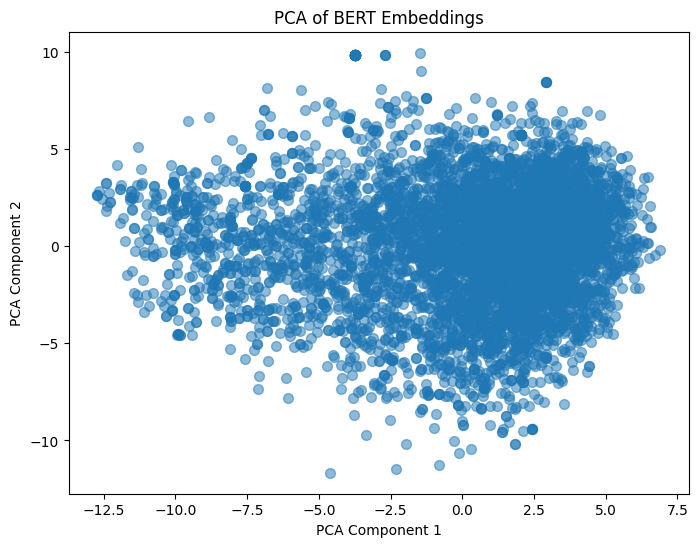

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

#initialize the PCA model
pca = PCA(n_components=2)

#standardize the embeddings before applying PCA
scaler = StandardScaler()
bert_embeddings_scaled = scaler.fit_transform(bert_embeddings)

#apply PCA to the scaled embeddings
bert_embeddings_pca = pca.fit_transform(bert_embeddings_scaled)
print(f"PCA embeddings shape: {bert_embeddings_pca.shape}")

#plot the PCA embeddings
plt.figure(figsize=(8, 6))
plt.scatter(bert_embeddings_pca[:, 0], bert_embeddings_pca[:, 1], s=50, alpha=0.5)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("PCA of BERT Embeddings")
plt.show()

### Exercise 1(i) (5 points)

Project and visualize the bert embedding with `TSNE`.

t-SNE embeddings shape: (5572, 2)


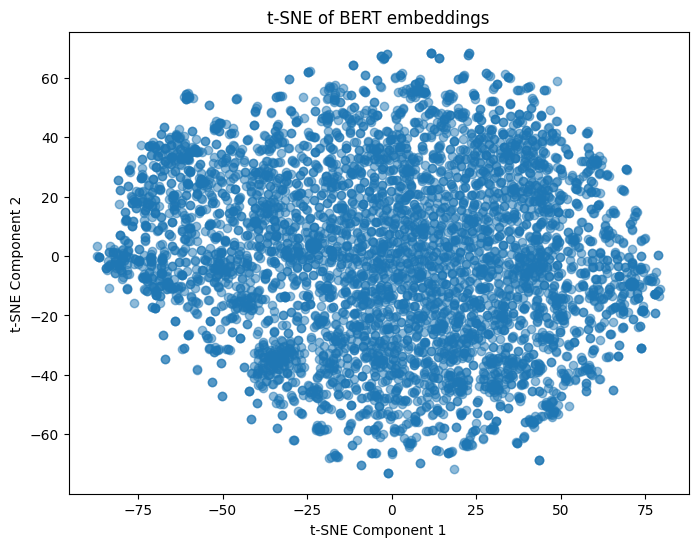

In [25]:
from sklearn.manifold import TSNE

#initialize the t-SNE model
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000) #using max_iter instead of n_iter

#apply the t-SNE model to the embeddings
bert_embeddings_tsne = tsne.fit_transform(bert_embeddings_scaled)
print(f"t-SNE embeddings shape: {bert_embeddings_tsne.shape}")

#plot the t-SNE results
plt.figure(figsize=(8, 6))
plt.scatter(bert_embeddings_tsne[:, 0], bert_embeddings_tsne[:, 1], alpha =.5)
plt.title("t-SNE of BERT embeddings")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.show()

In [23]:
import sklearn
print(sklearn.__version__)


1.9.1


### Exercise 1(j) (5 points)

Estimate the number of clusters on the bert embedding using silhouette, Calinski Harabasz, and Davies Bouldin scores. 

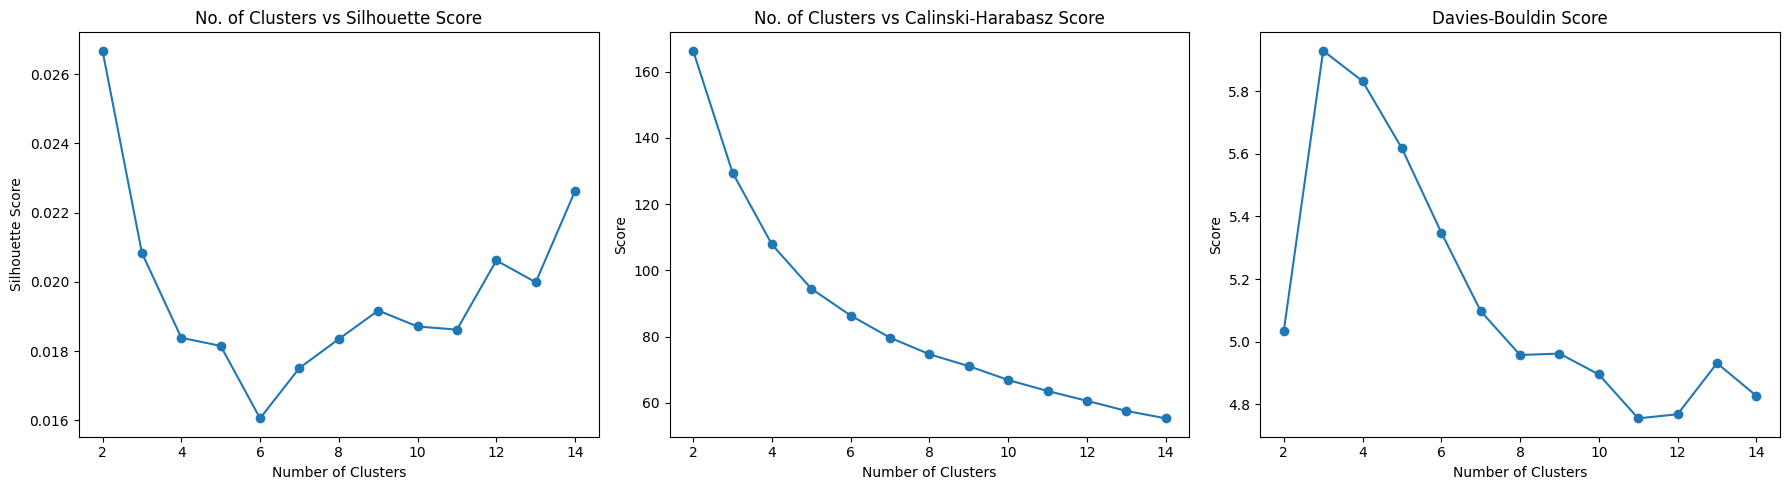

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

sil_scores, calinski_scores, davies_scores = [], [], []
for n_clusters in range(2, 15):

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=20)
    cluster_labels = kmeans.fit_predict(bert_embeddings_scaled)

    sil_scores.append(silhouette_score(bert_embeddings_scaled, cluster_labels))
    calinski_scores.append(calinski_harabasz_score(bert_embeddings_scaled, cluster_labels))
    davies_scores.append(davies_bouldin_score(bert_embeddings_scaled, cluster_labels))

plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1)
plt.plot(range(2, 15), sil_scores, marker='o')
plt.title("No. of Clusters vs Silhouette Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.subplot(1, 3, 2)
plt.plot(range(2, 15), calinski_scores, marker='o')
plt.title("No. of Clusters vs Calinski-Harabasz Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Score")

plt.subplot(1, 3, 3)
plt.plot(range(2, 15), davies_scores, marker='o')
plt.title("Davies-Bouldin Score")
plt.xlabel("Number of Clusters")
plt.ylabel("Score")

plt.tight_layout()
plt.show();

- SS: highest is best
- CH: highest is best
- DB: lowest is best